(lineage_tracing)=

# Lineage tracing

Score a fate map computed from expression against the fates that sister cells took, in the LARRY experiment of @Weinreb_2020: 130,887 mouse hematopoietic cells profiled on days 2, 4 and 6 of a culture started from barcoded progenitors. The page imports the authors' clones, measures their sizes, finds which fates share clones and labels each day-2 progenitor by the fates that its clone took. Fate probabilities from expression alone separate the clones that went mostly to neutrophils from those that went mostly to monocytes with an AUROC of 0.78. The AUROC is 0.68 for the quarter of progenitors earliest in pseudotime and 0.87 for the latest quarter, so expression predicts the fates of the earliest progenitors only weakly.

Cells that look alike can be heading for different fates. A single-cell transcriptome is a snapshot, so trajectory methods infer where a cell is heading from its place among other cells, and nothing in the snapshot shows what the cell became. Lineage tracing marks cells with a heritable barcode and profiles their descendants later; cells that share a barcode form a clone.

LARRY barcodes (Lineage And RNA RecoverY) are random 28-base sequences in the 3' UTR of an enhanced green fluorescent protein gene, delivered by lentivirus and read with each cell's transcriptome. @Weinreb_2020 barcoded mouse hematopoietic progenitors, sorted as Lin⁻Sca1⁺Kit⁺ (LSK) and Lin⁻Sca1⁻Kit⁺ cells, and cultured them for two days, during which they divided three times on average. They profiled half of the cells by single-cell RNA sequencing on day 2, and replated the rest and profiled them on days 4 and 6. A clone's day-2 cells and its later cells descend from one barcoded cell, so the later cells show which fates the day-2 cells' sisters took, the closest available measure of where a day-2 cell was heading.

This page is one of four on clonal analysis with `ds.clones`, each with its own source of clones. Here lentiviral barcodes mark the clones, and three time points follow them through hematopoiesis. The other three take their clones from phylogenetic trees reconstructed from prime-edited target sites in a mouse embryo ([](lineage_recorders.ipynb)), from somatic mitochondrial DNA mutations in a human tumor ([](mitochondrial_lineage_tracing.ipynb)), and from the receptor chains of T and B cells ([](immune_repertoires.ipynb)).

## Download the experiment

GEO series [GSE140802](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE140802) holds the in vitro experiment as sample GSM4185642: each cell's metadata, the clone matrix, the gene names and the expression matrix of 130,887 cells and 25,289 genes. The expression matrix, 2.1 GB of normalized values rather than counts, takes most of the download time. GEO's server can time out when it is busy, so each download resumes where a failed attempt stopped.

The example keeps the downloads and the store, about 7 GB together, in a temporary directory that Python deletes when the kernel stops. To keep them, or where the temporary directory is held in memory, set `output_dir` to a directory on disk.

In [1]:
# Modules to download, verify and open the published files.
import gzip
import hashlib
import http.client
import shutil
import time
from pathlib import Path
from tempfile import TemporaryDirectory
from urllib.error import HTTPError
from urllib.request import Request, urlopen

# Read the tables and the expression matrix, and score and draw the predictions.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from scipy import sparse
from sklearn.metrics import roc_auc_score, roc_curve

# Build the store and plot its results.
import cytearc
from cytearc.plotting import CategoricalScale, CellField, ColorScale

# Keep routine logs and progress bars out of the results.
cytearc.configure_output(level="WARNING", progress=False)

# Keep this example's downloads and store together.
work = TemporaryDirectory()
output_dir = Path(work.name)

Started: 2026-11-13T17:03:59.220432Z | Wall time: 6.151 s

In [2]:
# Pin the four GEO files so that a changed download cannot alter the example silently.
geo = (
    "https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM4185nnn/GSM4185642/suppl/"
    "GSM4185642_stateFate_inVitro_"
)
sources = {
    "metadata": (
        "metadata.txt.gz",
        "d98f67d01aa5d9aa3f8000466d6bf19bdb0596ecdc3eb7ef896b6f6ff49b55a2",
    ),
    "clones": (
        "clone_matrix.mtx.gz",
        "3ec9c54e9b1b53697f2a247609014c903e6670cc28a5cf0d8016810a101a7148",
    ),
    "genes": (
        "gene_names.txt.gz",
        "0e4513b828461b9ea1c48740a14686d417f06ff0137c4ae61a780a2c4ae0303d",
    ),
    "expression": (
        "normed_counts.mtx.gz",
        "f0736087e71f039baaa3d735f6fde87f391eb8df89c6a8223593e37ab48e2564",
    ),
}


# Copy a file in blocks without holding it in memory. GEO's server times out
# and refuses requests when it is busy, so resume where a failed attempt
# stopped, after a pause that grows with each attempt.
def download(url: str, path: Path, attempts: int = 6, pause: float = 30) -> None:
    for attempt in range(1, attempts + 1):
        received = path.stat().st_size if path.exists() else 0
        request = Request(url, headers={"Range": f"bytes={received}-"})
        try:
            with urlopen(request, timeout=60) as response:
                mode = "ab" if response.status == 206 else "wb"
                with path.open(mode) as target:
                    shutil.copyfileobj(response, target)
            return
        except HTTPError as error:
            # A range past the end means that an earlier attempt received every byte.
            if error.code == 416:
                return
            failure = error
        except (OSError, http.client.HTTPException) as error:
            failure = error
        if attempt < attempts:
            time.sleep(pause * attempt)
    raise ConnectionError(
        f"GEO did not serve {url} in {attempts} attempts; the last error was: {failure}"
    )


# Download each file and keep its path.
paths = {}
for name, (suffix, expected_digest) in sources.items():
    path = output_dir / f"GSM4185642_stateFate_inVitro_{suffix}"
    download(geo + suffix, path)

    # Reject a file whose contents differ from the verified source.
    with path.open("rb") as source:
        actual_digest = hashlib.file_digest(source, "sha256").hexdigest()
    if actual_digest != expected_digest:
        raise ValueError(f"Checksum mismatch for {path.name}")
    paths[name] = path

# Show the size of each completed download.
pd.Series(
    {name: path.stat().st_size / 1_000_000 for name, path in paths.items()},
    name="Downloaded MB",
).round(2)

metadata         2.22
clones           0.20
genes            0.07
expression    2065.70
Name: Downloaded MB, dtype: float64

Started: 2026-11-13T17:04:05.380076Z | Wall time: 72.722 s

## Build the store

The metadata holds one row per cell, in the same cell order as both matrices: its inDrops library, cell barcode, day, sorted starting population, the authors' cell type annotation, culture well and position in the authors' SPRING layout, a two-dimensional drawing of their graph of the cells' expression. Cell barcodes repeat across libraries, so name each cell by its library and barcode joined by `__`, as a merged store names cells.

In [3]:
# Read each cell's library, barcode, day, annotation and layout position.
metadata = pd.read_csv(paths["metadata"], sep="\t")

# Name each cell by its library and barcode, since barcodes repeat across libraries.
cell_ids = metadata["Library"] + "__" + metadata["Cell barcode"]
if not cell_ids.is_unique:
    raise ValueError("Two cells share a library and a barcode")

# Read the gene names, one per column of the expression matrix.
genes = pd.read_csv(paths["genes"], header=None)[0]

# Count the cells of each annotation on each day.
pd.crosstab(
    metadata["Cell type annotation"],
    metadata["Time point"].astype(int).rename("Day"),
    margins=True,
    margins_name="All",
)

Day,2,4,6,All
Cell type annotation,,,,
Baso,187,3247,6721,10155
Ccr7_DC,57,100,84,241
Eos,15,189,351,555
Erythroid,100,153,433,686
Lymphoid,144,583,130,857
Mast,40,579,1965,2584
Meg,97,632,1367,2096
Monocyte,950,7505,10727,19182
Neutrophil,1068,6721,14448,22237


Started: 2026-11-13T17:05:18.122669Z | Wall time: 0.404 s

On day 2, 25,575 of the 28,249 cells are undifferentiated; by day 6, 17,891 of 54,140 are, and neutrophils (14,448), monocytes (10,727) and basophils (6,721) are the largest mature types.

CyteArc's Matrix Market reader reads counts, while this matrix holds normalized values, so read its entries with pandas, a chunk at a time, and write the store with `SparseToZarr`. The file lists its entries gene by gene, so gather them into a matrix with cells as rows before writing it.

In [4]:
# Read the matrix's dimensions, which follow its header comments.
with gzip.open(paths["expression"], "rt") as handle:
    header_lines = 0
    for line in handle:
        header_lines += 1
        if not line.startswith("%"):
            n_cells, n_genes, n_entries = map(int, line.split())
            break

# Check that the matrix holds the cells of the metadata and the listed genes.
if (n_cells, n_genes) != (len(metadata), len(genes)):
    raise ValueError("The matrix does not match the metadata and the gene names")

# Read the entries a chunk at a time into 32-bit positions and values.
rows = np.empty(n_entries, dtype=np.int32)
columns = np.empty(n_entries, dtype=np.int32)
values = np.empty(n_entries, dtype=np.float32)
position = 0
for chunk in pd.read_csv(
    paths["expression"],
    sep=" ",
    header=None,
    skiprows=header_lines,
    names=["cell", "gene", "value"],
    dtype={"cell": np.int32, "gene": np.int32, "value": np.float32},
    chunksize=10_000_000,
):
    end = position + len(chunk)
    rows[position:end] = chunk["cell"].to_numpy() - 1
    columns[position:end] = chunk["gene"].to_numpy() - 1
    values[position:end] = chunk["value"].to_numpy()
    position = end

# Check that the file held every entry that its header declares.
if position != n_entries:
    raise ValueError(f"Read {position} entries, but the header declares {n_entries}")

# Gather the entries into a matrix with cells as rows.
expression = sparse.csr_matrix((values, (rows, columns)), shape=(n_cells, n_genes))
del rows, columns, values

# Show the matrix's size and the range of the cells' totals.
totals = np.asarray(expression.sum(axis=1)).ravel()
pd.Series(
    {
        "Cells": n_cells,
        "Genes": n_genes,
        "Nonzero values": n_entries,
        "Smallest cell total": round(float(totals.min()), 2),
        "Largest cell total": round(float(totals.max()), 2),
    },
    name="Expression matrix",
    dtype=object,
)

Cells                     130887
Genes                      25289
Nonzero values         176867560
Smallest cell total      2878.75
Largest cell total       2878.75
Name: Expression matrix, dtype: object

Started: 2026-11-13T17:05:18.530063Z | Wall time: 86.301 s

Every cell's values sum to 2,878.75, so the 177 million nonzero values are each cell's counts scaled to one common total. `values="normalized"` records that the assay holds such values, so the store refuses steps that need counts; CyteArc would reach the same decision from the values if the argument were left out.

`SparseToZarr` holds the whole matrix in memory while it writes the store, shard by shard. When CyteArc's default count layout does not fit the memory budget, an import stops before it writes and names the largest `CountMatrixPolicy` that fits. `policy="fit"` keeps the default layout where it fits and otherwise writes that smaller layout instead of stopping. Smaller shards make later gene-wise reads slower, so on a machine with more memory, give the import a larger [`mem_budget`](../concepts/memory_and_execution.md#memory-budget) instead.

In [5]:
# Write the store in the largest count layout that fits the memory budget.
store_path = output_dir / "larry_in_vitro.zarr"
writer = cytearc.SparseToZarr(
    expression,
    str(store_path),
    cell_ids=cell_ids.to_numpy(),
    feature_ids=genes.to_numpy(),
    policy="fit",
    values="normalized",
)
writer.dump()

# Report the layout that the import chose and the store's size, then release
# the matrix, which the writer holds.
store_bytes = sum(file.stat().st_size for file in store_path.rglob("*") if file.is_file())
print(
    f"Count shards of {writer.policy.unitBytes / 1e6:,.0f} MB within a memory "
    f"budget of {writer.resources.memoryBytes / 2**30:.1f} GiB; "
    f"the store takes {store_bytes / 1e9:.1f} GB on disk"
)
del writer, expression

# Open the store.
ds = cytearc.DataStore(str(store_path), default_assay="RNA")

# Record each cell's metadata under short column names, in the store's cell order.
ds.cells.insert("library", metadata["Library"].to_numpy())
ds.cells.insert("starting_population", metadata["Starting population"].to_numpy())
ds.cells.insert("cell_type", metadata["Cell type annotation"].to_numpy())
ds.cells.insert("day", metadata["Time point"].astype(int).to_numpy())
ds.cells.insert("well", metadata["Well"].to_numpy())

# Keep the SPRING layout as the two columns that an embedding plot reads.
ds.cells.insert("SPRING1", metadata["SPRING-x"].to_numpy())
ds.cells.insert("SPRING2", metadata["SPRING-y"].to_numpy())
ds

Count shards of 1,000 MB within a memory budget of 6.0 GiB; the store takes 5.1 GB on disk


DataStore has 130887 (130887) cells with 1 assays: RNA
   Cell metadata:
            'I', 'ids', 'names', 'RNA_nCounts', 'RNA_nFeatures', 
            'RNA_percentMito', 'RNA_percentRibo', 'SPRING1', 'SPRING2', 'cell_type', 
            'day', 'library', 'starting_population', 'well'
   RNA assay has 25289 features and following metadata:
            'I', 'ids', 'names', 'dropOuts', 'nCells'

Started: 2026-11-13T17:06:44.847096Z | Wall time: 72.743 s

With a 6.0 GiB memory budget, the default layout fits this matrix: the import wrote count shards of 1,000 MB, and the store takes 5.1 GB on disk.

Color the SPRING layout by annotation and by day to see where each day's cells sit among the cell types.

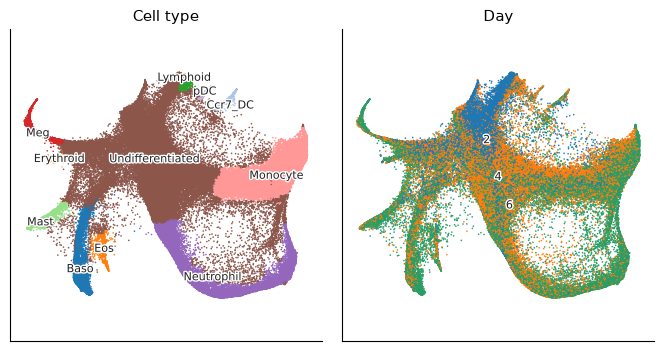

Started: 2026-11-13T17:07:57.594594Z | Wall time: 2.099 s

In [6]:
# Draw the cells on the authors' layout by annotation and by day.
ds.plots.embedding(
    layout_key="SPRING",
    color_by=[
        CellField("cell_type", kind="categorical", label="Cell type"),
        CellField("day", kind="categorical", label="Day"),
    ],
    n_columns=2,
    legend_loc="on_data",
)

Day-2 cells sit at the top of the layout, among the undifferentiated progenitors, and day-4 and day-6 cells fill the branches of the mature types: neutrophils and monocytes on the right, basophils, eosinophils and mast cells at the bottom left, megakaryocytes and erythroid cells on the left, and dendritic and lymphoid cells at the top.

## Import the clones

The clone matrix holds a 1 where a cell belongs to a clone, with its cells in the order of the metadata, so `import_clones` reads the metadata beside the matrix as its list of cells, and `columns` names the two columns that make each cell's ID. The clones join a frozen cell selection, an immutable record of the cells that an analysis used, so that a later change to the store's cell columns cannot change what the clones refer to.

In [7]:
# Freeze every cell of the store as the cells that the clones join.
cells = ds.snapshot_cell_selection("I")

# Import the clones; the metadata beside the matrix names their cells.
clones = ds.clones.import_clones(
    paths["clones"],
    cell_selection=cells,
    columns={"cell": ["Library", "Cell barcode"]},
)

# Check that every cell of the clone matrix joined a cell of the store.
joined = ds.artifacts.inspect(clones).diagnostics
pd.Series(
    {
        "Cells in the clone matrix": joined["fileBarcodes"],
        "Cells that name no cell of the store": joined["unmatchedBarcodes"],
        "Cells with a clone": joined["cellsWithClone"],
    },
    name="Clone import",
)

Cells in the clone matrix               130887
Cells that name no cell of the store         0
Cells with a clone                       49302
Name: Clone import, dtype: int64

Started: 2026-11-13T17:07:59.697424Z | Wall time: 1.214 s

In [8]:
# Summarize the clones by their sizes.
table = ds.clones.load_clones(clones)
pd.Series(
    {
        "Clones": len(table.clones),
        "Smallest clone": table.clones["n_cells"].min(),
        "Median clone": table.clones["n_cells"].median(),
        "Largest clone": table.clones["n_cells"].max(),
    },
    name="Cells",
    dtype=object,
)

Clones            5864
Smallest clone       2
Median clone       4.0
Largest clone      177
Name: Cells, dtype: object

Started: 2026-11-13T17:08:00.915284Z | Wall time: 0.120 s

All 130,887 cells of the clone matrix joined the store, and 49,302 of them, 38%, belong to one of 5,864 clones of 2 to 177 cells. The GEO deposit lists only clones of two or more cells, so a cell without a clone may be the only sampled cell of its clone.

## Measure clone sizes on each day

A clone's cells on one day are a sample of its descendants on that day, so comparing the days shows how the clones expand.

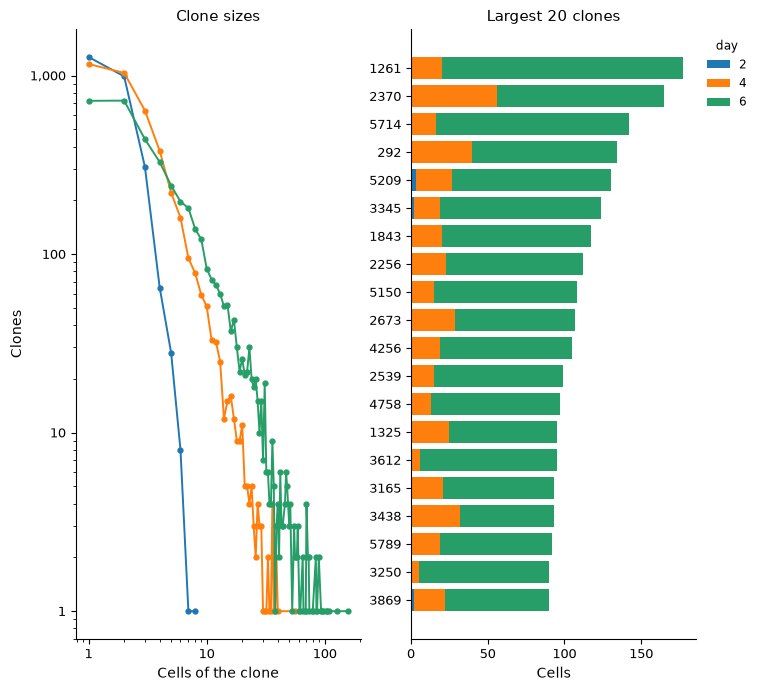

Started: 2026-11-13T17:08:01.038675Z | Wall time: 0.998 s

In [9]:
# Draw the number of clones of each size on each day, and the largest clones by day.
ds.plots.clone_abundance(clones, group_by="day")

In [10]:
# Read each cell's ID, annotation and day in the store's order.
ids = ds.cells.fetch("ids", key="I")
cell_type = ds.cells.fetch("cell_type", key="I")
day = ds.cells.fetch("day", key="I")
cell_info = pd.DataFrame({"cell_type": cell_type, "day": day}, index=ids)

# Count each clone's cells on each day.
clone_cells = table.cells.dropna(subset=["clone"]).join(cell_info)
day_sizes = clone_cells.groupby(["day", "clone"], observed=True).size()

# Summarize each day's clones by their sizes on that day.
by_day = day_sizes.groupby(level="day")
small = (day_sizes <= 2).groupby(level="day").mean() * 100
pd.DataFrame(
    {"Clones": by_day.size(), "Of one or two cells (%)": small, "Largest": by_day.max()}
).round(1).rename_axis("Day")

,Clones,Of one or two cells (%),Largest
Day,,,
2,2672,84.6,8
4,4101,53.5,56
6,3956,36.6,157


Started: 2026-11-13T17:08:02.040843Z | Wall time: 0.152 s

On day 2, 85% of the 2,672 clones hold one or two sampled cells, and the largest holds 8. The share of such small clones falls to 54% on day 4 and 37% on day 6, and the largest holds 56 and then 157 cells; most cells of the 20 largest clones come from day 6.

## Find the fates that share clones

Fate coupling measures how often two cell types share clones. For each clone, `clones.coupling` takes each type's share of the clone's cells, after scaling each type by its number of cells with a clone, and measures the cosine between two types' shares across the clones. This index is CoSpar's default [@Wang_2022], and it counts every clone once whatever its size. Each pair also gets a z-score against a null that shuffles the types among the cells with a clone. Measure the coupling among the day-6 cells of the ten mature types, and draw it under a dendrogram that joins first the types that couple most strongly.

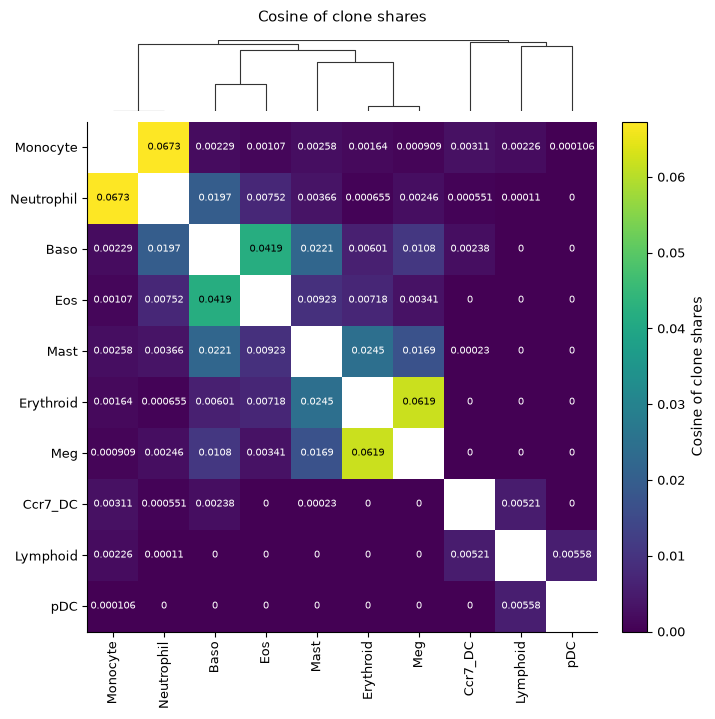

Started: 2026-11-13T17:08:02.196401Z | Wall time: 4.545 s

In [11]:
# Mark the day-6 cells of the mature types.
ds.cells.insert("day6_mature", (day == 6) & (cell_type != "Undifferentiated"))

# Measure how strongly each pair of mature types shares clones on day 6.
coupling = ds.clones.coupling(
    clones,
    group_by="cell_type",
    cell_selection=ds.snapshot_cell_selection("day6_mature"),
)
ds.plots.clone_coupling(coupling, value="coupling")

In [12]:
# Show the most coupled pairs beside the couplings of shuffled labels.
top_pairs = coupling.pairs.sort_values("coupling", ascending=False).head(6)
top_pairs.set_index(["group_1", "group_2"]).round(3)

coupling  null_mean  null_sd  z_score
group_1   group_2                                          
Monocyte  Neutrophil     0.067      0.217    0.007  -20.483
Erythroid Meg            0.062      0.054    0.007    1.217
Baso      Eos            0.042      0.024    0.002    8.035
Erythroid Mast           0.024      0.054    0.006   -5.214
Baso      Mast           0.022      0.117    0.006  -15.993
          Neutrophil     0.020      0.199    0.007  -24.595

Started: 2026-11-13T17:08:06.745658Z | Wall time: 0.021 s

In [13]:
# Count the mature types among each clone's day-6 cells.
day6_types = (
    clone_cells.query("day == 6 and cell_type != 'Undifferentiated'")
    .groupby("clone", observed=True)["cell_type"]
    .agg(["size", "nunique"])
    .query("size >= 2")
)

# Count the pairs above and below their null, and the clones that hold one
# mature type.
pd.Series(
    {
        "Pairs of mature types": len(coupling.pairs),
        "Pairs that couple more than their null": int(
            (coupling.pairs["z_score"] > 0).sum()
        ),
        "Pairs that couple less than their null": int(
            (coupling.pairs["z_score"] < 0).sum()
        ),
        "Clones of two or more day-6 mature cells": len(day6_types),
        "Clones of one mature type": int((day6_types["nunique"] == 1).sum()),
    },
    name="Count",
)

Pairs of mature types                         45
Pairs that couple more than their null         2
Pairs that couple less than their null        43
Clones of two or more day-6 mature cells    2055
Clones of one mature type                   1455
Name: Count, dtype: int64

Started: 2026-11-13T17:08:06.769556Z | Wall time: 0.037 s

Neutrophils with monocytes couple most strongly (0.067), then erythroid cells with megakaryocytes (0.062) and basophils with eosinophils (0.042). The dendrogram joins the fates in three branches: neutrophils with monocytes; basophils, eosinophils, mast cells, erythroid cells and megakaryocytes; and the dendritic and lymphoid cells. @Weinreb_2020 found that the clones that cell types share in culture follow how close the types are in expression (r = 0.93), and that hierarchies built from either differ only in where mast cells branch.

Only basophils with eosinophils share clones more than chance would give, 8.0 standard deviations above their null mean; erythroid cells with megakaryocytes sit 1.2 standard deviations above theirs, within the null's spread. The other 43 pairs couple less than their null: by day 6, 1,455 of the 2,055 clones with two or more mature cells hold a single mature type, while shuffling spreads each clone over several types. Neutrophils with monocytes couple at 0.067 against a null mean of 0.217, 20.5 null standard deviations below it. The z-scores here mostly measure how committed the clones are, so this page ranks pairs by the cosine. Where cuts whose clones differ in size are compared, as in [](lineage_recorders.ipynb), or where pairs of similar coupling differ in how far they beat chance, as in [](mitochondrial_lineage_tracing.ipynb), the z-score is the value to compare, and those pages draw it.

## Label each progenitor by its clone's fates

`fate_bias` gives each early cell the share of its clone's late cells in each fate and its dominant fate, the fate that holds the most of them. Take the undifferentiated day-2 cells as the early cells, and the day-4 and day-6 cells of the mature types as the late cells, whose types are the fates.

In [14]:
# Mark the day-2 progenitors as the early cells, and the day-4 and day-6 cells
# of the mature types as the late cells.
ds.cells.insert("day2_progenitor", (day == 2) & (cell_type == "Undifferentiated"))
ds.cells.insert("later_mature", (day > 2) & (cell_type != "Undifferentiated"))

# Label each progenitor by the fates of its clone's late cells.
bias = ds.clones.fate_bias(
    clones,
    group_by="cell_type",
    early=ds.snapshot_cell_selection("day2_progenitor"),
    late=ds.snapshot_cell_selection("later_mature"),
)
fates = ds.clones.load_fate_bias(bias)

# Follow the progenitors from a clone to a dominant fate.
traced = ds.artifacts.inspect(bias).diagnostics
pd.Series(
    {
        "Day-2 progenitors": len(fates.cells),
        "With a clone": int(fates.cells["clone"].notna().sum()),
        "Clone without late cells": traced["earlyCellsWithoutLateCells"],
        "Clone's late cells tie between fates": traced["earlyCellsWithTiedFates"],
        "With a dominant fate": int(fates.cells["fate"].notna().sum()),
    },
    name="Cells",
)

Day-2 progenitors                       25575
With a clone                             4199
Clone without late cells                 2219
Clone's late cells tie between fates       59
With a dominant fate                     1921
Name: Cells, dtype: int64

Started: 2026-11-13T17:08:06.809558Z | Wall time: 1.213 s

In [15]:
# Count the progenitors by their clone's dominant fate.
dominant = fates.cells["fate"].value_counts()
dominant.rename_axis("Dominant fate").rename("Day-2 progenitors")

Dominant fate
Neutrophil    730
Monocyte      632
Baso          259
Meg           115
Lymphoid       87
Mast           45
Erythroid      20
Eos            15
Ccr7_DC        11
pDC             7
Name: Day-2 progenitors, dtype: int64

Started: 2026-11-13T17:08:08.026004Z | Wall time: 0.012 s

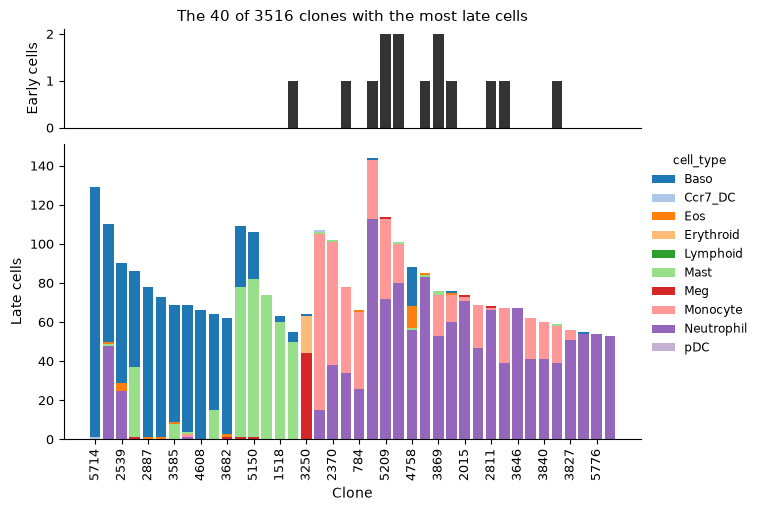

Started: 2026-11-13T17:08:08.040946Z | Wall time: 0.961 s

In [16]:
# Draw the late cells of the clones with the most late cells, by fate.
ds.plots.clone_fate_bias(bias)

Of the 25,575 day-2 progenitors, 4,199 have a clone. The clones of 2,219 of them have no late cells and those of 59 tie between fates, which leaves 1,921 progenitors with a dominant fate. Neutrophils or monocytes dominate the clones of 1,362 of them, 71%, and basophils those of 259. Among the 40 clones with the most late cells, many mix two types, mostly neutrophils with monocytes or basophils with mast cells. Most of these clones have no sampled day-2 progenitor, so the largest clones add few progenitor labels. A clone with few late cells gives a noisy share of each fate.

## Compute fate probabilities from expression

A fate map computed from expression predicts the same outcomes without a barcode, and the clones test how well it does. The map walks a neighbor graph of the cells, which the RNA recipe, `ds.pipeline.rna`, builds: the recipe selects highly variable genes, normalizes each cell to a common total and takes logs, reduces the genes with PCA and connects each cell to its nearest neighbors. Normalizing values already scaled to one total gives the values that the counts would give. Passing the frozen selection of every cell, rather than a cell column, skips the recipe's quality filter, so the graph keeps every cell that the authors kept. Doublet scoring needs counts, which the deposit lacks, so turn it off, along with the cell-cycle scores, UMAP, clusters and markers, which this page does not use.

In [17]:
# Build the neighbor graph of every cell from its expression.
run = ds.pipeline.rna(
    label="larry",
    cells=cells,
    cell_cycle=False,
    umap=False,
    leiden=False,
    doublets=False,
    markers=False,
)

Started: 2026-11-13T17:08:09.005775Z | Wall time: 111.263 s

Pseudotime orders the graph from source cells to sink cells by population balance analysis [@Weinreb_2018], and fate probabilities give each cell the chance that a walk along the graph, moving mostly forward in pseudotime, reaches each sink first, as the [fate mapping tutorial](fate_mapping.ipynb) explains. Take the day-2 progenitors as the source, sharing a total weight of -1, and the cells of the ten mature types as the sinks, sharing +1.

In [18]:
# Weight the day-2 progenitors as the source and the mature cells as the sinks.
mature_types = sorted(set(cell_type) - {"Undifferentiated"})
source = (cell_type == "Undifferentiated") & (day == 2)
sink = np.isin(cell_type, mature_types)
source_sink_vector = np.zeros(len(cell_type), dtype=float)
source_sink_vector[source] = -1.0 / source.sum()
source_sink_vector[sink] = 1.0 / sink.sum()

# Order the graph from the progenitors to the mature types.
graph = run["connectivity_map"]
pseudotime = ds.trajectory.pseudotime(graph, ss_vec=source_sink_vector)

# Compute each cell's probability of reaching each mature type.
type_labels = ds.snapshot_cluster_labels(
    "cell_type", cell_selection=run["analysis_cell_selection"]
)
fate_map = ds.trajectory.fate(pseudotime, type_labels, sinks=mature_types)
probabilities = ds.trajectory.load_fate(fate_map)

# Label the probabilities of the scored cells by fate.
predicted = pd.DataFrame(
    probabilities.values,
    columns=[str(label) for label in probabilities.sink_labels],
    index=ids,
)[probabilities.valid]

# Count the cells of the graph and the cells with probabilities.
pd.Series(
    {"Graph cells": len(probabilities.valid), "Scored cells": len(predicted)},
    name="Cells",
)

Graph cells     130887
Scored cells    130887
Name: Cells, dtype: int64

Started: 2026-11-13T17:10:00.272383Z | Wall time: 18.570 s

All 130,887 cells lie in one connected graph and have fate probabilities. The mature cells are the sinks, so their probabilities follow from the choice of sinks; the progenitors, which no sink fixes, are the cells to score.

## Score the predictions against the clones

Neutrophils or monocytes dominate the clones of most progenitors with a dominant fate, and @Weinreb_2020 benchmarked fate prediction methods on the choice between them. Give each progenitor two neutrophil shares. The predicted share is its probability of reaching neutrophils divided by its probability of reaching neutrophils or monocytes; the traced share is the fraction of neutrophils among its clone's late neutrophils and monocytes. Draw both for the progenitors whose clones went mostly to neutrophils or to monocytes.

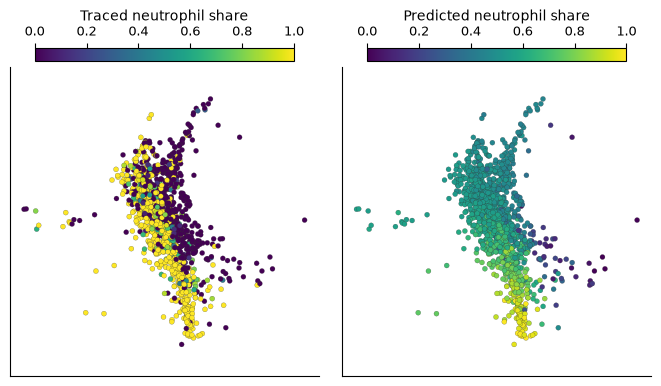

Started: 2026-11-13T17:10:18.846258Z | Wall time: 14.101 s

In [19]:
# Give each progenitor its predicted and its traced neutrophil share.
predicted_share = predicted["Neutrophil"] / (
    predicted["Neutrophil"] + predicted["Monocyte"]
)
traced_share = fates.fractions["Neutrophil"] / (
    fates.fractions["Neutrophil"] + fates.fractions["Monocyte"]
)
ds.cells.insert("predicted_neutrophil_share", predicted_share.reindex(ids).to_numpy())
ds.cells.insert("traced_neutrophil_share", traced_share.reindex(ids).to_numpy())

# Mark the progenitors whose clones went mostly to neutrophils or to monocytes.
outcome = fates.cells["fate"].isin(["Neutrophil", "Monocyte"])
ds.cells.insert(
    "neutrophil_or_monocyte", np.isin(ids, fates.cells.index[outcome.to_numpy()])
)

# Draw both shares of those progenitors on one scale.
ds.plots.embedding(
    layout_key="SPRING",
    color_by=[
        CellField(
            "traced_neutrophil_share",
            kind="continuous",
            label="Traced neutrophil share",
        ),
        CellField(
            "predicted_neutrophil_share",
            kind="continuous",
            label="Predicted neutrophil share",
        ),
    ],
    subset_by="neutrophil_or_monocyte",
    color_scale=ColorScale(scope="shared", vmin=0, vmax=1),
    n_columns=2,
)

Most traced shares are 0 or 1, since most clones went to one of the two types. At the top of the layout, the progenitors of neutrophil clones and of monocyte clones sit side by side, and the predicted shares there stay near one half. The predictions move toward 1 only for progenitors further down, toward the neutrophils, and toward 0 for the few on the right, toward the monocytes.

Score the predictions by clone, since a clone's progenitors share one traced outcome: average the predicted shares of each clone's progenitors, and measure how well the averages separate the clones that went mostly to neutrophils from those that went mostly to monocytes by the area under the ROC curve (AUROC), 0.5 for chance and 1 for a perfect separation. Resample the clones for a 95% interval.

In [20]:
# Pair each scored progenitor's predicted share with its clone and dominant fate.
scored = fates.cells[outcome].join(predicted_share.rename("predicted"), how="inner")
scored["neutrophil"] = scored["fate"] == "Neutrophil"


# Average the predicted shares of each clone's progenitors, which share one
# traced outcome.
def clone_means(progenitors: pd.DataFrame) -> pd.DataFrame:
    grouped = progenitors.groupby("clone", observed=True)[["neutrophil", "predicted"]]
    return grouped.mean()


# Score how well the clones' mean predicted shares separate neutrophil clones
# from monocyte clones, with a 95% interval from clones drawn with replacement.
def clone_auroc(progenitors: pd.DataFrame) -> pd.Series:
    by_clone = clone_means(progenitors)
    neutrophil = by_clone["neutrophil"].to_numpy() == 1
    share = by_clone["predicted"].to_numpy()
    samples = np.random.default_rng(0).integers(0, len(share), (2_000, len(share)))
    draws = [roc_auc_score(neutrophil[sample], share[sample]) for sample in samples]
    return pd.Series(
        {
            "Day-2 progenitors": len(progenitors),
            "Clones": len(share),
            "AUROC": round(roc_auc_score(neutrophil, share), 2),
            "Lower 95%": round(np.quantile(draws, 0.025), 2),
            "Upper 95%": round(np.quantile(draws, 0.975), 2),
        },
        dtype=object,
    )


# Score every progenitor of a neutrophil or monocyte clone.
clone_auroc(scored).rename("Neutrophil or monocyte clones")

Day-2 progenitors    1362
Clones                916
AUROC                0.78
Lower 95%            0.75
Upper 95%            0.81
Name: Neutrophil or monocyte clones, dtype: object

Started: 2026-11-13T17:10:32.950769Z | Wall time: 4.454 s

The mean predicted shares of the 916 clones of these 1,362 progenitors separate the two outcomes with an AUROC of 0.78 (95% interval 0.75 to 0.81): in 78% of the pairs of a neutrophil clone and a monocyte clone, the neutrophil clone has the higher mean predicted share.

## Follow the separation through pseudotime

Progenitors early in pseudotime sit closer to the source and further from every fate. Split the scored progenitors into quarters by pseudotime. In each quarter, compare the predicted shares of progenitors from neutrophil clones with those from monocyte clones, and score the quarter's clones. Then draw the shares of each quarter beside its ROC curve.

In [21]:
# Split the scored progenitors into quarters by pseudotime, from the earliest.
progenitor_time = pd.Series(
    ds.trajectory.load_pseudotime(pseudotime).values, index=ids
).reindex(scored.index)
quarter = pd.qcut(progenitor_time, 4, labels=["First", "Second", "Third", "Fourth"])

# Take the median predicted share of the progenitors of neutrophil clones and of
# monocyte clones in each quarter.
medians = (
    scored.groupby([quarter, "fate"], observed=True)["predicted"].median().unstack()
)

# Score each quarter beside its pseudotime range and medians.
pd.concat(
    [
        progenitor_time.groupby(quarter, observed=True)
        .agg(lambda times: f"{times.min():.2f} to {times.max():.2f}")
        .rename("Pseudotime"),
        medians[["Neutrophil", "Monocyte"]].round(2).add_prefix("Median share, "),
        scored.groupby(quarter, observed=True).apply(clone_auroc),
    ],
    axis=1,
).rename_axis("Quarter")

,Pseudotime,"Median share, Neutrophil","Median share, Monocyte",Day-2 progenitors,Clones,AUROC,Lower 95%,Upper 95%
Quarter,,,,,,,,
First,0.01 to 0.15,0.51,0.49,341,287,0.68,0.62,0.74
Second,0.15 to 0.20,0.55,0.54,340,280,0.67,0.60,0.73
Third,0.20 to 0.28,0.67,0.60,340,243,0.79,0.73,0.84
Fourth,0.28 to 0.64,0.84,0.54,341,236,0.87,0.82,0.92


Started: 2026-11-13T17:10:37.407910Z | Wall time: 17.698 s

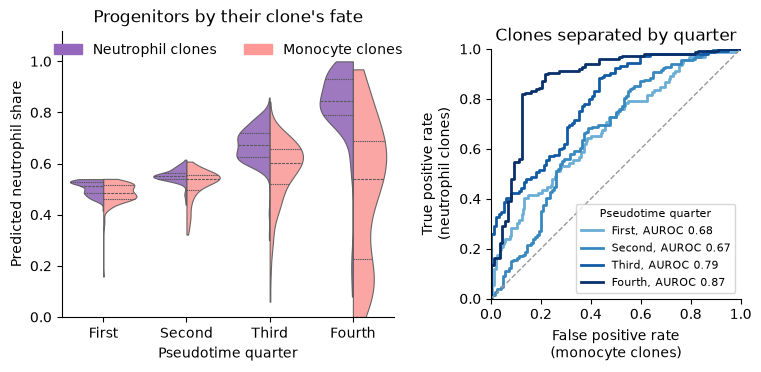

Started: 2026-11-13T17:10:55.109444Z | Wall time: 1.347 s

In [22]:
# Record each scored progenitor's pseudotime quarter and its clone's fate, so
# that the store's plots can group and split the progenitors by them.
ds.cells.insert("pseudotime_quarter", quarter, key="neutrophil_or_monocyte")
ds.cells.insert(
    "clone_fate", scored["fate"].astype(str), key="neutrophil_or_monocyte"
)

# Compare the predicted shares of the two kinds of clone in each quarter, with
# the fates in the colors that the figures above give the cell types.
fate_colors = {"Neutrophil": "#9467bd", "Monocyte": "#ff9896"}
figure, (violin_axis, roc_axis) = plt.subplots(
    1, 2, figsize=(7.5, 3.6), layout="constrained", width_ratios=[4, 3]
)
ds.plots.distribution(
    CellField("predicted_neutrophil_share"),
    grouping=CellField(
        "pseudotime_quarter", kind="categorical", label="Pseudotime quarter"
    ),
    groups=["First", "Second", "Third", "Fourth"],
    split_by="clone_fate",
    split_scale=CategoricalScale(order=tuple(fate_colors), palette=fate_colors),
    subset_by="neutrophil_or_monocyte",
    max_points=0,
    show_legend=False,
    target=violin_axis,
    show=False,
)
violin_axis.set(
    ylim=(0, 1.12),
    yticks=np.linspace(0, 1, 6),
    ylabel="Predicted neutrophil share",
    title="Progenitors by their clone's fate",
)
plt.setp(violin_axis.get_xticklabels(), rotation=0, ha="center")
violin_axis.legend(
    handles=[
        Patch(color=color, label=f"{fate} clones")
        for fate, color in fate_colors.items()
    ],
    loc="upper center",
    ncols=2,
    frameon=False,
)

# Draw each quarter's ROC curve over the clones, darker for later quarters.
quarter_colors = plt.get_cmap("Blues")(np.linspace(0.5, 1.0, 4))
for (name, progenitors), color in zip(
    scored.groupby(quarter, observed=True), quarter_colors, strict=True
):
    by_clone = clone_means(progenitors)
    neutrophil = by_clone["neutrophil"] == 1
    false_positive, true_positive, _ = roc_curve(neutrophil, by_clone["predicted"])
    area = roc_auc_score(neutrophil, by_clone["predicted"])
    roc_axis.plot(
        false_positive,
        true_positive,
        color=color,
        linewidth=2,
        label=f"{name}, AUROC {area:.2f}",
    )
roc_axis.plot([0, 1], [0, 1], color="0.6", linestyle="--", linewidth=1)
roc_axis.set(
    xlim=(0, 1),
    ylim=(0, 1),
    aspect="equal",
    xlabel="False positive rate\n(monocyte clones)",
    ylabel="True positive rate\n(neutrophil clones)",
    title="Clones separated by quarter",
)
roc_axis.legend(title="Pseudotime quarter", loc="lower right", fontsize=8, title_fontsize=8)
plt.show()

In the earliest quarter, the predicted shares of the two kinds of progenitor barely differ, with medians of 0.51 and 0.49, yet they still rank the clones better than chance, with an AUROC of 0.68 (95% interval 0.62 to 0.74); the second quarter scores about the same, 0.67. The separation grows in the later two quarters: the medians reach 0.67 and 0.60 in the third (AUROC 0.79) and 0.84 and 0.54 in the fourth (AUROC 0.87, 95% interval 0.82 to 0.92). Most of the gain comes from the progenitors of neutrophil clones, whose median share rises from 0.51 in the first quarter to 0.84 in the fourth. The median share of the progenitors of monocyte clones stays between 0.49 and 0.60, and in the fourth quarter their shares spread from near 0 to near 1. The fate map recognizes the progenitors bound for neutrophils once they have progressed in pseudotime, and separates the fates of the earliest progenitors only weakly.

@Weinreb_2020 found a similar pattern with population balance analysis, WaddingtonOT and FateID. Their predictions broadly agreed with the clonal fates as cells began to mature, but generally missed the split between neutrophil and monocyte potential among the earliest (Cd34⁺) progenitors, where their correlation with the traced shares stayed below r = 0.26, against r = 0.5 for predictions from held-out clonal data. The two analyses score differently, by an AUROC over clones here and a correlation over cells there, and they choose the earliest progenitors differently, by pseudotime here and by Cd34 expression there, so they agree in direction rather than in their numbers.

The [clones API reference](/api/clones.html) describes every clone summary used here, the import of clones from other lineage tracing tools, and clones called from barcode reads.